In [28]:
import pandas as pd
import os

import numpy as np
import matplotlib.pyplot as plt

import iminuit
from iminuit import Minuit
from iminuit.cost import LeastSquares

In [29]:
def find_row_with_string(file_path, target_string):
    with open(file_path, 'r') as file:
        for i, line in enumerate(file):
            if target_string in line:
                return i
    return -1  # Return -1 if the string is not found

hc = 1239.84193 # eV nm

Franta-150K.csv
Franta-200K.csv
Franta-250K.csv
Franta-293K.csv


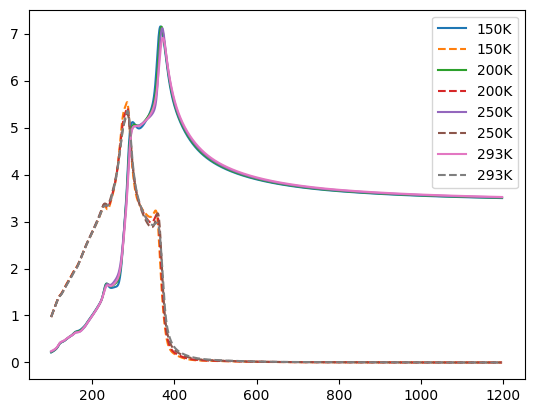

In [30]:
filesPath = "franta_data/"
allFiles = os.listdir(filesPath)
sortedFiles = sorted(allFiles, key=lambda x: int(x.split("-")[1].split("K")[0]))

class TempData:
    def __init__(self, temperature, wl, n, k):
        self.temperature = temperature
        self.wl = wl
        self.eV = hc/wl
        self.n = n
        self.k = k
        
dataSets = []

for file in sortedFiles:
    print(file)
    temperature = file.split("-")[1].split("K")[0]
    
    rowK = find_row_with_string(filesPath+file, "wl,k")
    
    wl, n = np.loadtxt(filesPath+file, unpack=True, skiprows=1, delimiter=",", max_rows=rowK-2)
    wl *= 1e3
    wlMask = (wl > 100) & (wl < 1200)
    
    wlk, k = np.loadtxt(filesPath+file, unpack=True, skiprows=rowK+1, delimiter=",")
    wlk *= 1e3

    dataSet = TempData(temperature, wl[wlMask], n[wlMask], k[wlMask])
    dataSets.append(dataSet)
    np.savetxt("franta_reformatted/" + f"Franta-{temperature}K.txt", np.array([dataSet.wl, dataSet.n, dataSet.k]).T, delimiter=",", header="wl,n,k", comments="", fmt="%.4f")


for dataSet in dataSets:
    plt.plot(dataSet.wl, dataSet.n, label=dataSet.temperature+"K")
    
    plt.plot(dataSet.wl, dataSet.k, label=dataSet.temperature+"K", linestyle="--")

plt.legend()
# vuye20 = dataSets[0]